ШАГ 1. ДАННЫЕ И ВРЕМЕННОЙ РЯД

В этой части я загружаю датасет Online Retail, смотрю на его структуру и выбираю товар для анализа. Для временного ряда мне нужны код товара, дата покупки и количество проданных единиц. Дальше я агрегирую продажи по дням, неделям и месяцам, чтобы посмотреть на ряд в разных масштабах.

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.tsa.seasonal import seasonal_decompose, STL, MSTL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

import statsmodels.api as sm

from pathlib import Path

from scipy.signal import (
    find_peaks,
    detrend,
    butter,
    sosfiltfilt,
    welch,
    freqz
)

from scipy.stats import linregress

import pywt

import io
import zipfile


np.random.seed(42)


item_id = '85099B'

In [2]:
def load_online_retail(local_path="Online Retail.xlsx"):
    """Загружает Online Retail из локального XLSX или официального архива UCI."""
    local_path = Path(local_path)
    if local_path.exists():
        return pd.read_excel(local_path)

    url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"
    try:
        import requests
        response = requests.get(url, timeout=60)
        response.raise_for_status()
        with zipfile.ZipFile(io.BytesIO(response.content)) as archive:
            xlsx_name = next(
                name for name in archive.namelist()
                if name.lower().endswith(".xlsx")
            )
            with archive.open(xlsx_name) as file:
                return pd.read_excel(file)
    except Exception as exc:
        raise RuntimeError(
            "Не удалось загрузить датасет автоматически. "
            "Скачайте Online Retail.xlsx с UCI и положите рядом с ноутбуком."
        ) from exc

df = load_online_retail()
print(f"Размер исходной таблицы: {df.shape[0]:,} строк × {df.shape[1]} столбцов")
display(df.head())




Размер исходной таблицы: 541,909 строк × 8 столбцов


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
df['StockCode'].value_counts().head()

StockCode
85123A    2313
22423     2203
85099B    2159
47566     1727
20725     1639
Name: count, dtype: int64

In [4]:
df['Quantity'].describe()

count    541909.000000
mean          9.552250
std         218.081158
min      -80995.000000
25%           1.000000
50%           3.000000
75%          10.000000
max       80995.000000
Name: Quantity, dtype: float64

In [5]:
df[df['StockCode'] == item_id]['Description'].value_counts()

Description
JUMBO BAG RED RETROSPOT    2159
Name: count, dtype: int64

Я убрал отрицательные значения Quantity, потому что они относятся к возвратам или отменам. В этой работе я хочу анализировать именно продажи, поэтому оставляю только положительные количества.

In [38]:
sales = (
    df[(df['StockCode'] == "85123A") & (df['Quantity'] > 0 )]
    .set_index('InvoiceDate')[['Quantity']].resample('D').sum()
)
sales.shape

(374, 1)

In [45]:
sales.describe()

,Quantity
count,374.000000
mean,111.401070
std,301.662177
min,0.000000
25%,15.250000
50%,58.000000
75%,116.750000
max,4015.000000


,Aggregation,InvoiceDate,Quantity
369,Daily,2011-12-05,298
370,Daily,2011-12-06,39
371,Daily,2011-12-07,200
372,Daily,2011-12-08,108
373,Daily,2011-12-09,4
423,Weekly,2011-11-13,575
424,Weekly,2011-11-20,1322
425,Weekly,2011-11-27,898
426,Weekly,2011-12-04,726
427,Weekly,2011-12-11,649


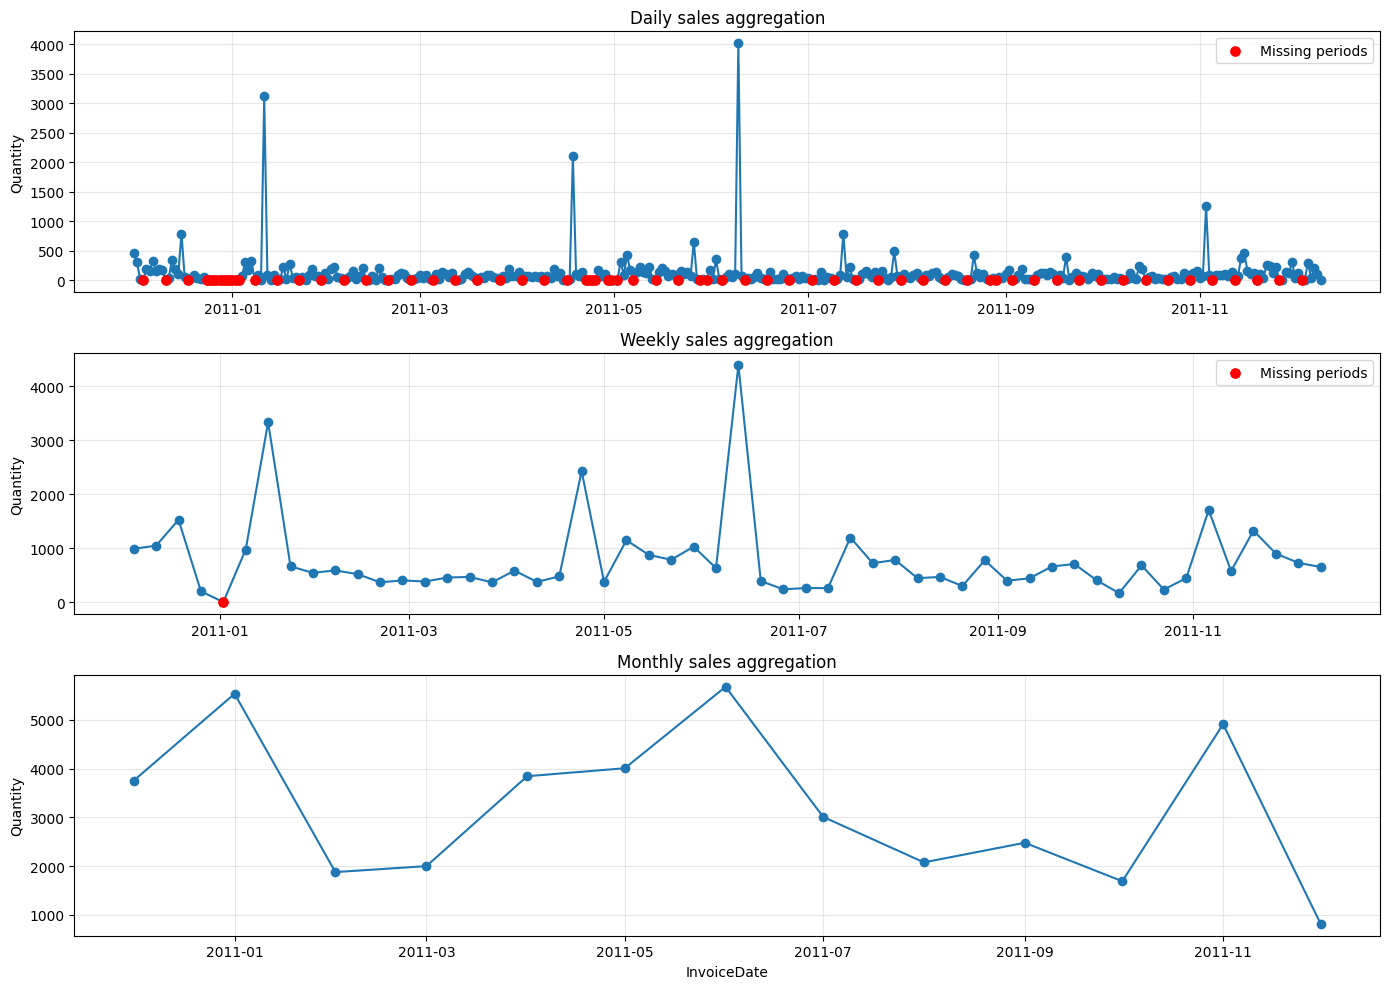

In [40]:
sales_daily = sales.resample('D').sum()
sales_weekly = sales.resample('W').sum()
sales_monthly = sales.resample('MS').sum()

aggregated_sales = {
    'Daily': sales_daily,
    'Weekly': sales_weekly,
    'Monthly': sales_monthly,
}

sales_by_period = pd.concat(
    [series.assign(Aggregation=name) for name, series in aggregated_sales.items()]
).rename_axis('InvoiceDate').reset_index()[['Aggregation', 'InvoiceDate', 'Quantity']]

missing_sales = {
    name: series[series['Quantity'].eq(0)].index
    for name, series in aggregated_sales.items()
}

missing_summary = pd.DataFrame({
    'Aggregation': missing_sales.keys(),
    'Missing periods count': [len(dates) for dates in missing_sales.values()],
    'Missing dates': [', '.join(dates.strftime('%Y-%m-%d')) for dates in missing_sales.values()],
})

display(sales_by_period.groupby('Aggregation').tail(5))


fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=False)

for ax, (title, series) in zip(axes, aggregated_sales.items()):
    ax.plot(series.index, series['Quantity'], marker='o', linewidth=1.5)
    missing_dates = missing_sales[title]
    if len(missing_dates) > 0:
        ax.scatter(
            missing_dates,
            series.loc[missing_dates, 'Quantity'],
            color='red',
            s=45,
            zorder=3,
            label='Missing periods',
        )
        ax.legend()
    ax.set_title(f'{title} sales aggregation')
    ax.set_ylabel('Quantity')
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel('InvoiceDate')
plt.tight_layout()
plt.show()

In [41]:
missing_summary


,Aggregation,Missing periods count,Missing dates
0,Daily,69,"2010-12-04, 2010-12-11, 2010-12-18, 2010-12-24..."
1,Weekly,1,2011-01-02
2,Monthly,0,


In [42]:
missing_summary.iloc[0]['Missing dates']


'2010-12-04, 2010-12-11, 2010-12-18, 2010-12-24, 2010-12-25, 2010-12-26, 2010-12-27, 2010-12-28, 2010-12-29, 2010-12-30, 2010-12-31, 2011-01-01, 2011-01-02, 2011-01-03, 2011-01-08, 2011-01-15, 2011-01-22, 2011-01-29, 2011-02-05, 2011-02-12, 2011-02-19, 2011-02-26, 2011-03-05, 2011-03-12, 2011-03-19, 2011-03-26, 2011-04-02, 2011-04-09, 2011-04-16, 2011-04-22, 2011-04-23, 2011-04-24, 2011-04-25, 2011-04-29, 2011-04-30, 2011-05-02, 2011-05-07, 2011-05-14, 2011-05-21, 2011-05-28, 2011-05-30, 2011-06-04, 2011-06-11, 2011-06-18, 2011-06-25, 2011-07-02, 2011-07-09, 2011-07-16, 2011-07-23, 2011-07-30, 2011-08-06, 2011-08-13, 2011-08-20, 2011-08-27, 2011-08-29, 2011-09-03, 2011-09-10, 2011-09-17, 2011-09-24, 2011-10-01, 2011-10-08, 2011-10-15, 2011-10-22, 2011-10-29, 2011-11-05, 2011-11-12, 2011-11-19, 2011-11-26, 2011-12-03'

In [43]:
missing_daily_dates = pd.Series(missing_sales['Daily'], name='InvoiceDate')

weekday_order = [
    'Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'
]

missing_weekday_stats = (
    missing_daily_dates
    .dt.day_name()
    .value_counts()
    .reindex(weekday_order, fill_value=0)
    .rename_axis('Weekday')
    .reset_index(name='Missing days count')
)

display(missing_weekday_stats)

,Weekday,Missing days count
0,Monday,6
1,Tuesday,1
2,Wednesday,1
3,Thursday,1
4,Friday,4
5,Saturday,53
6,Sunday,3


Большая часть нулевых значений попадает на субботы. Скорее всего, это связано с особенностями работы магазина или с тем, что в эти дни по выбранному товару не было продаж. Еще отдельно виден период около Нового года. Эти нули я дальше учитываю как календарно объяснимые, а остальные проверяю внимательнее.

Количество аномалий: 17


,InvoiceDate,Quantity,q25,q75,lower_bound,upper_bound
0,2010-12-16,790,141.25,225.75,-112.25,479.25
1,2011-01-05,304,36.00,57.00,-27.00,120.00
2,2011-01-11,3114,74.50,270.75,-514.25,859.50
3,2011-04-12,198,61.50,75.50,19.50,117.50
4,2011-04-14,127,61.50,75.50,19.50,117.50
5,2011-04-18,2102,48.75,73.25,-24.75,146.75
6,2011-05-26,653,87.25,153.75,-112.25,353.25
7,2011-06-09,4015,28.25,123.75,-258.25,410.25
8,2011-07-12,786,16.75,63.50,-123.50,203.75
9,2011-07-14,224,19.50,64.50,-115.50,199.50


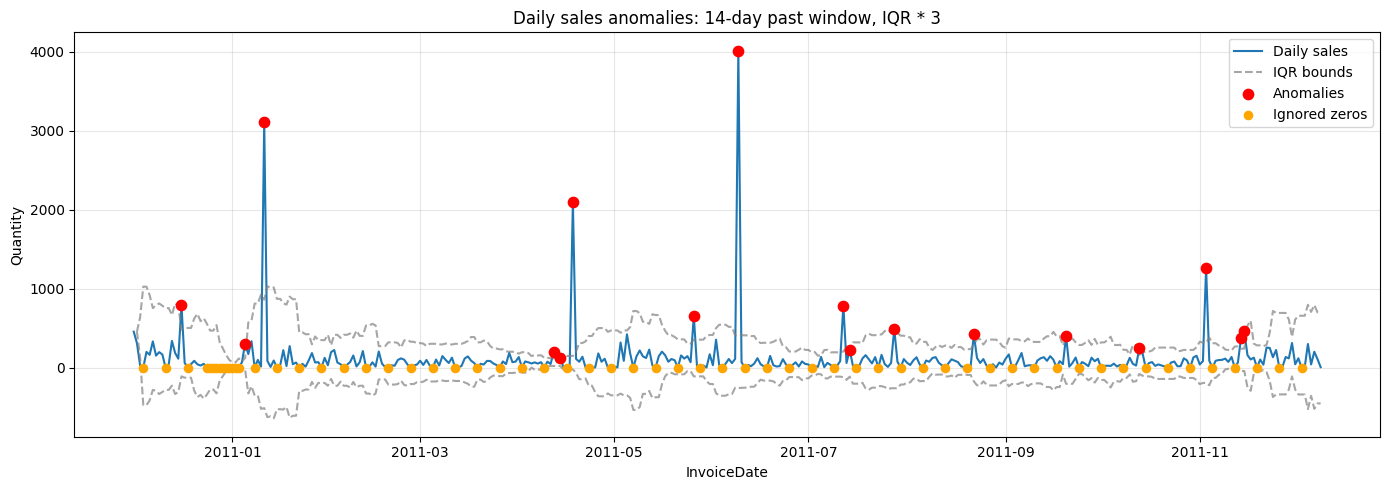

In [50]:
window = 14
iqr_multiplier = 3

daily_anomalies = sales_daily.copy()
holiday_start = pd.Timestamp('2010-12-24')
holiday_end = pd.Timestamp('2011-01-03')

is_zero = daily_anomalies['Quantity'].eq(0)
is_saturday = daily_anomalies.index.dayofweek == 5
is_holiday_period = (
    (daily_anomalies.index >= holiday_start)
    & (daily_anomalies.index <= holiday_end)
)
ignored_zero_mask = is_zero & (is_saturday | is_holiday_period)

daily_anomalies['Quantity_for_iqr'] = daily_anomalies['Quantity'].mask(ignored_zero_mask)
has_full_past_window = (
    daily_anomalies['Quantity']
    .shift(1)
    .rolling(window=window, min_periods=window)
    .count()
    .eq(window)
)
past_window = daily_anomalies['Quantity_for_iqr'].shift(1).rolling(window=window, min_periods=1)

daily_anomalies['q25'] = past_window.quantile(0.25)
daily_anomalies['q75'] = past_window.quantile(0.75)
daily_anomalies['iqr'] = daily_anomalies['q75'] - daily_anomalies['q25']
daily_anomalies['lower_bound'] = daily_anomalies['q25'] - iqr_multiplier * daily_anomalies['iqr']
daily_anomalies['upper_bound'] = daily_anomalies['q75'] + iqr_multiplier * daily_anomalies['iqr']
daily_anomalies['is_anomaly'] = (
    has_full_past_window
    & ~ignored_zero_mask
    & (
        daily_anomalies['Quantity'].lt(daily_anomalies['lower_bound'])
        | daily_anomalies['Quantity'].gt(daily_anomalies['upper_bound'])
    )
)

ignored_zero_points = daily_anomalies[ignored_zero_mask].reset_index()[['InvoiceDate', 'Quantity']]
anomaly_points = daily_anomalies[daily_anomalies['is_anomaly']].copy()
anomaly_points = anomaly_points.reset_index()[[
    'InvoiceDate', 'Quantity', 'q25', 'q75', 'lower_bound', 'upper_bound'
]]


print(f'Количество аномалий: {len(anomaly_points)}')
display(anomaly_points)

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(daily_anomalies.index, daily_anomalies['Quantity'], label='Daily sales', linewidth=1.5)
ax.plot(daily_anomalies.index, daily_anomalies['lower_bound'], '--', color='gray', alpha=0.7, label='IQR bounds')
ax.plot(daily_anomalies.index, daily_anomalies['upper_bound'], '--', color='gray', alpha=0.7)

if not anomaly_points.empty:
    ax.scatter(
        anomaly_points['InvoiceDate'],
        anomaly_points['Quantity'],
        color='red',
        s=55,
        zorder=3,
        label='Anomalies',
    )

if not ignored_zero_points.empty:
    ax.scatter(
        ignored_zero_points['InvoiceDate'],
        ignored_zero_points['Quantity'],
        color='orange',
        s=35,
        zorder=2,
        label='Ignored zeros',
    )

ax.set_title(f'Daily sales anomalies: {window}-day past window, IQR * {iqr_multiplier}')
ax.set_xlabel('InvoiceDate')
ax.set_ylabel('Quantity')
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

In [52]:
keep_zero_mask = daily_anomalies['Quantity'].ne(0) | ignored_zero_mask
dropped_zero_points = daily_anomalies[
    daily_anomalies['Quantity'].eq(0) & ~ignored_zero_mask
].reset_index()[['InvoiceDate', 'Quantity']]

sales_clean = daily_anomalies.loc[
    ~daily_anomalies['is_anomaly'] & keep_zero_mask,
    ['Quantity'],
].copy()

sales_clean.index.name = 'InvoiceDate'



ИТОГОВАЯ ПОДГОТОВКА РЯДА

Для дальнейшего анализа я оставляю ряд sales_clean. Сначала дневной ряд строится на полном календаре, поэтому дни без продаж получают значение 0.

Нули по субботам и в период с 2010-12-25 по 2011-01-03 я оставляю, потому что их можно объяснить с помощью анализа календаря. Остальные нули удаляю из итогового ряда, так как они похожи на нерегулярные пропуски продаж.

Аномалии я ищу по правилу IQR на окне из 14 предыдущих дней. Текущая точка в окно не входит. Границы считаются как Q1 минус 3 IQR и Q3 плюс 3 IQR. Календарные нули в этом расчете не участвуют.

Количество нулевых значений в итоговом ряду: 62


,InvoiceDate,Quantity
0,2010-12-04,0
1,2010-12-11,0
2,2010-12-18,0
3,2010-12-24,0
4,2010-12-25,0
...,...,...
57,2011-11-05,0
58,2011-11-12,0
59,2011-11-19,0
60,2011-11-26,0


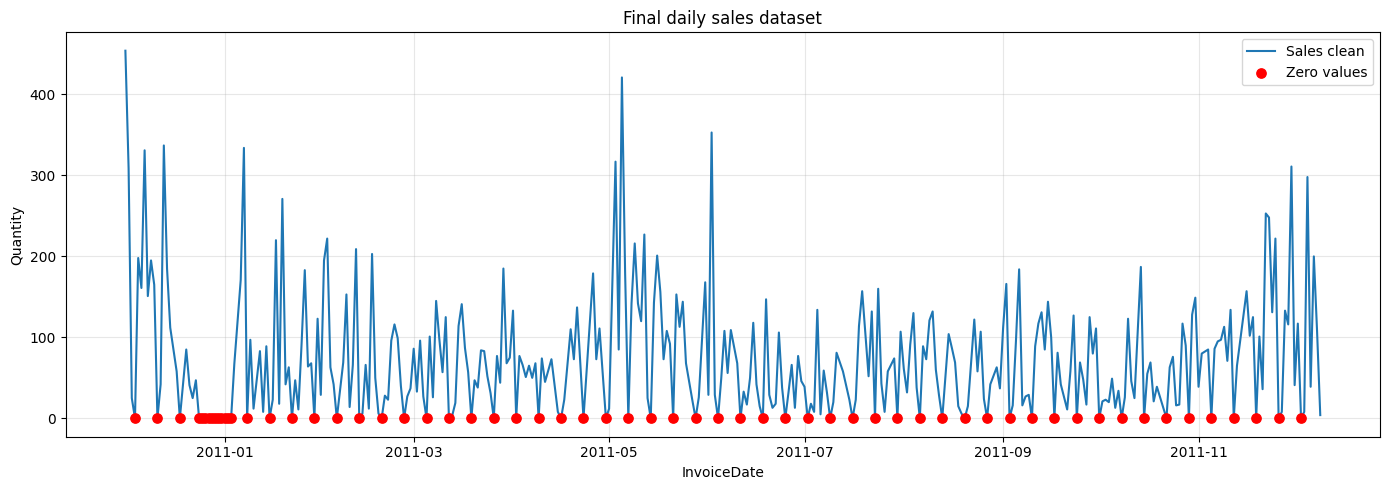

In [53]:
zero_points_clean = sales_clean[sales_clean['Quantity'].eq(0)]

print(f'Количество нулевых значений в итоговом ряду: {len(zero_points_clean)}')
display(zero_points_clean.reset_index())

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(sales_clean.index, sales_clean['Quantity'], linewidth=1.5, label='Sales clean')

if not zero_points_clean.empty:
    ax.scatter(
        zero_points_clean.index,
        zero_points_clean['Quantity'],
        color='red',
        s=45,
        zorder=3,
        label='Zero values',
    )

ax.set_title('Final daily sales dataset')
ax.set_xlabel('InvoiceDate')
ax.set_ylabel('Quantity')
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

,Метрика,Значение
0,Среднее,73.422857
1,Дисперсия,5754.548473
2,Стандартное отклонение,75.858740


,Месяц,Средние продажи
0,Январь,72.931034
1,Февраль,67.035714
2,Март,64.483871
3,Апрель,61.565217
4,Май,119.750000
5,Июнь,57.275862
6,Июль,53.892857
7,Август,57.103448
8,Сентябрь,71.724138
9,Октябрь,48.200000


,День_недели,Средние продажи
0,Понедельник,83.173913
1,Вторник,102.208333
2,Среда,100.490566
3,Четверг,98.586957
4,Пятница,76.076923
5,Суббота,0.000000
6,Воскресенье,60.557692


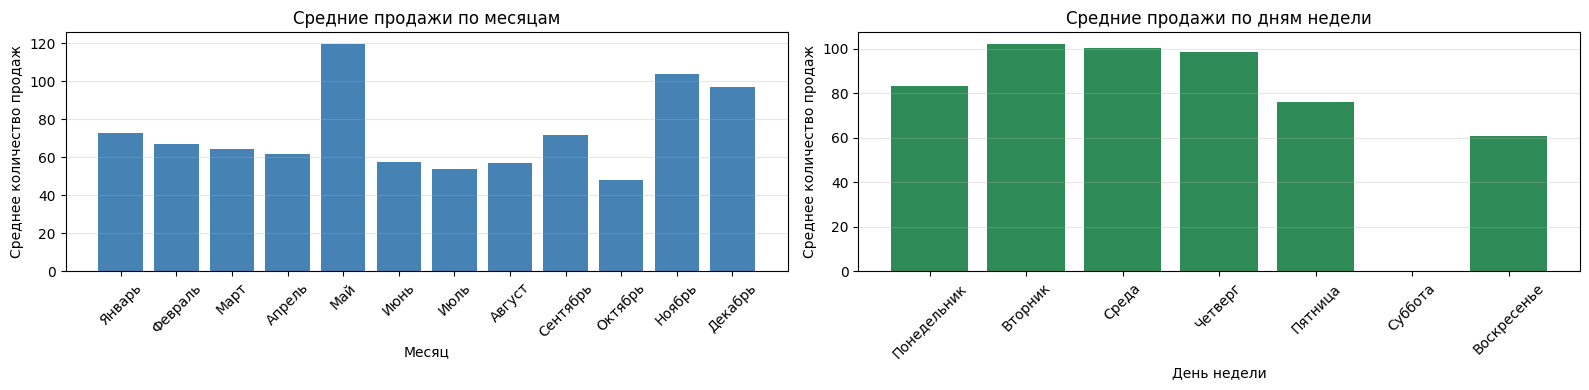

In [61]:
sales_analysis = sales_clean.copy()

basic_stats = pd.DataFrame({
    'Метрика': ['Среднее', 'Дисперсия', 'Стандартное отклонение'],
    'Значение': [
        sales_analysis['Quantity'].mean(),
        sales_analysis['Quantity'].var(),
        sales_analysis['Quantity'].std(),
    ],
})

display(basic_stats)

month_names = {
    1: 'Январь', 2: 'Февраль', 3: 'Март', 4: 'Апрель',
    5: 'Май', 6: 'Июнь', 7: 'Июль', 8: 'Август',
    9: 'Сентябрь', 10: 'Октябрь', 11: 'Ноябрь', 12: 'Декабрь',
}

weekday_names = {
    0: 'Понедельник', 1: 'Вторник', 2: 'Среда', 3: 'Четверг',
    4: 'Пятница', 5: 'Суббота', 6: 'Воскресенье',
}

monthly_average_sales = (
    sales_analysis
    .assign(Месяц=sales_analysis.index.month.map(month_names))
    .groupby('Месяц', sort=False)['Quantity']
    .mean()
    .reindex(month_names.values())
    .dropna()
    .reset_index(name='Средние продажи')
)

weekday_average_sales = (
    sales_analysis
    .assign(День_недели=sales_analysis.index.dayofweek.map(weekday_names))
    .groupby('День_недели', sort=False)['Quantity']
    .mean()
    .reindex(weekday_names.values())
    .dropna()
    .reset_index(name='Средние продажи')
)

display(monthly_average_sales)
display(weekday_average_sales)

fig, axes = plt.subplots(1, 2, figsize=(16, 4))

axes[0].bar(monthly_average_sales['Месяц'], monthly_average_sales['Средние продажи'], color='steelblue')
axes[0].set_title('Средние продажи по месяцам')
axes[0].set_xlabel('Месяц')
axes[0].set_ylabel('Среднее количество продаж')
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(axis='y', alpha=0.3)

axes[1].bar(weekday_average_sales['День_недели'], weekday_average_sales['Средние продажи'], color='seagreen')
axes[1].set_title('Средние продажи по дням недели')
axes[1].set_xlabel('День недели')
axes[1].set_ylabel('Среднее количество продаж')
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


Количество наблюдений на дневной сетке: 374
Главная частота: 0.1417 цикла в день
Соответствующий период: 7.06 дня
Амплитуда главной частоты: 24.13
Амплитуда около недельной частоты: 24.13 (период 7.06 дня)


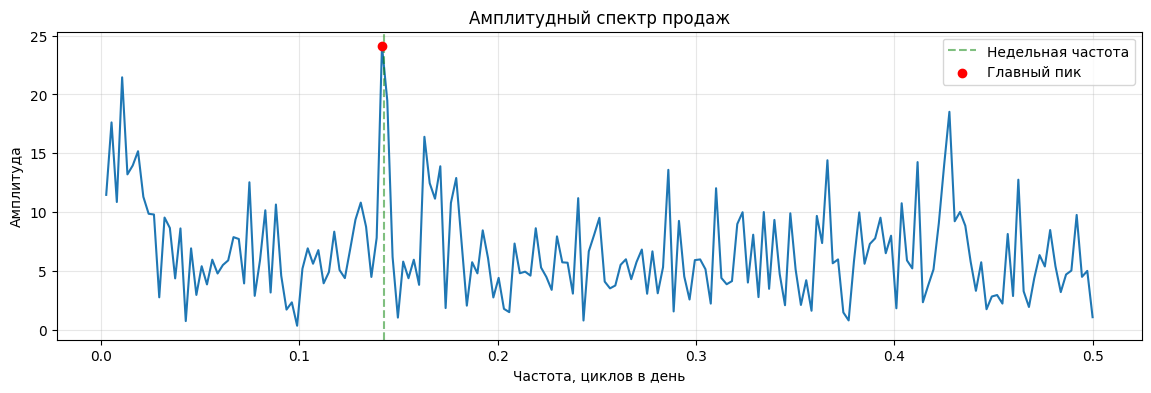

In [60]:
sales_spectral = sales_clean.asfreq('D')
n = len(sales_spectral)

y = sales_spectral['Quantity'].to_numpy(dtype=float)
y = np.nan_to_num(y, nan=0.0)
y = y - y.mean()
spectrum = np.fft.rfft(y)

freqs = np.fft.rfftfreq(n, d=1)
amplitude = np.abs(spectrum) / n
if n % 2 == 0:
    amplitude[1:-1] *= 2
else:
    amplitude[1:] *= 2

dominant_idx = np.argmax(amplitude[1:]) + 1
dominant_frequency = freqs[dominant_idx]
dominant_period = 1 / dominant_frequency if dominant_frequency != 0 else np.nan
dominant_amplitude = amplitude[dominant_idx]

weekly_frequency = 1 / 7
weekly_idx = np.argmin(np.abs(freqs - weekly_frequency))
weekly_amplitude = amplitude[weekly_idx]
weekly_period = 1 / freqs[weekly_idx]

print(f'Количество наблюдений на дневной сетке: {n}')
print(f'Главная частота: {dominant_frequency:.4f} цикла в день')
print(f'Соответствующий период: {dominant_period:.2f} дня')
print(f'Амплитуда главной частоты: {dominant_amplitude:.2f}')
print(f'Амплитуда около недельной частоты: {weekly_amplitude:.2f} (период {weekly_period:.2f} дня)')

plt.figure(figsize=(14, 4))
plt.plot(freqs[1:], amplitude[1:])
plt.axvline(weekly_frequency, ls='--', c='g', alpha=.5, label='Недельная частота')
plt.scatter(freqs[dominant_idx], dominant_amplitude, color='red', zorder=3, label='Главный пик')
plt.xlabel('Частота, циклов в день')
plt.ylabel('Амплитуда')
plt.title('Амплитудный спектр продаж')
plt.grid(alpha=0.3)
plt.legend()
plt.show()


Максимальная амплитуда CWT: 141.57
Максимальная мощность CWT: 20040.88
Максимум мощности находится около периода 6.43 дня, дата: 2010-12-05


C:\Users\Pavel\AppData\Roaming\Python\Python310\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


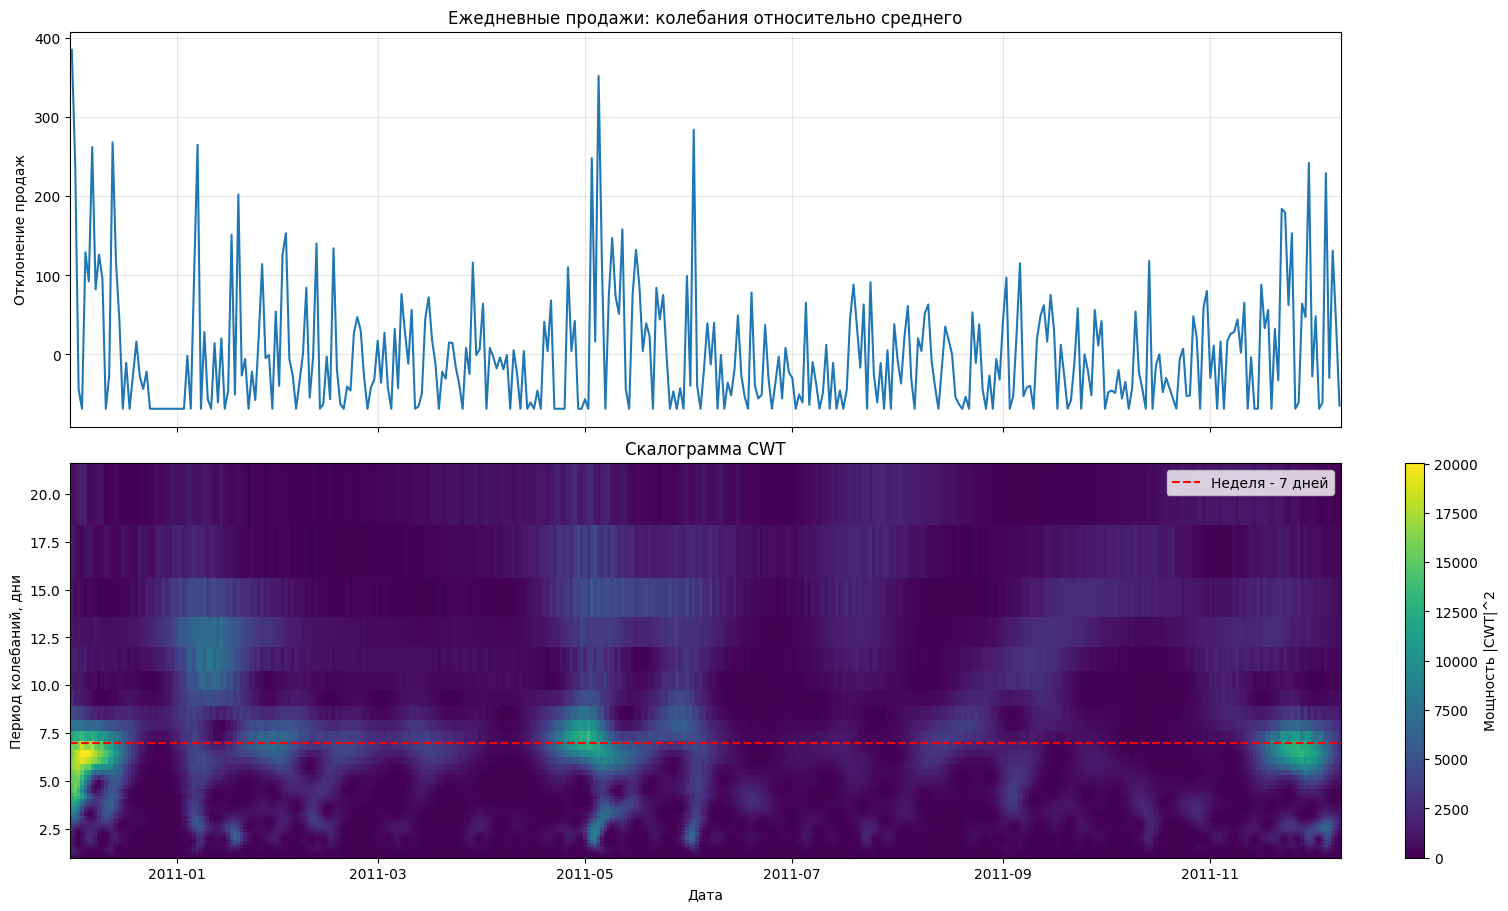

In [59]:
sales_spectral = sales_clean.asfreq('D')

y = sales_spectral['Quantity'].to_numpy(dtype=float)

# Если в ряду есть пропуски, заменим их нулями.
# Это подходит, если пропуски означают отсутствие продаж.
y = np.nan_to_num(y, nan=0.0)

# Уберем средний уровень.
y = y - y.mean()

# Зададим масштабы, соответствующие разным периодам.
wavelet = 'cmor1.5-1.0'
target_freqs = np.linspace(1 / 20, 1, 100)
scales = pywt.frequency2scale(wavelet, target_freqs)

# Рассчитаем CWT.
coefficients, frequencies = pywt.cwt(
    y,
    scales,
    wavelet,
    sampling_period=1,  # один отсчет = один день
)

# Переведем частоты в периоды, дни.
periods = 1 / frequencies

# Построим скалограмму.
cwt_amplitude = np.abs(coefficients)
power = cwt_amplitude ** 2
max_power_idx = np.unravel_index(np.argmax(power), power.shape)
max_power_period = periods[max_power_idx[0]]
max_power_date = sales_spectral.index[max_power_idx[1]]
max_cwt_amplitude = cwt_amplitude[max_power_idx]
max_cwt_power = power[max_power_idx]

print(f'Максимальная амплитуда CWT: {max_cwt_amplitude:.2f}')
print(f'Максимальная мощность CWT: {max_cwt_power:.2f}')
print(f'Максимум мощности находится около периода {max_power_period:.2f} дня, дата: {max_power_date:%Y-%m-%d}')

fig, axes = plt.subplots(
    2, 1, figsize=(15, 9),
    sharex=True,
    layout='constrained',
)

# Исходный ряд.
axes[0].plot(sales_spectral.index, y)
axes[0].set_title('Ежедневные продажи: колебания относительно среднего')
axes[0].set_ylabel('Отклонение продаж')
axes[0].grid(alpha=0.3)

# Скалограмма: цвет показывает мощность колебаний.
mesh = axes[1].pcolormesh(
    sales_spectral.index,
    periods,
    power,
    shading='auto',
    cmap='viridis',
)

axes[1].set_title('Скалограмма CWT')
axes[1].set_ylabel('Период колебаний, дни')
axes[1].set_xlabel('Дата')
axes[1].axhline(
    7,
    color='red',
    linestyle='--',
    linewidth=1.5,
    label='Неделя - 7 дней',
)
axes[1].legend()

fig.colorbar(mesh, ax=axes[1], label='Мощность |CWT|^2')
plt.show()


ИНТЕРПРЕТАЦИЯ ГРАФИКОВ

По средним продажам по месяцам основные пики получились в мае, ноябре и декабре. Для товара WHITE HANGING HEART T-LIGHT HOLDER это выглядит логично: это декоративный подсвечник для дома и подарков, поэтому высокий спрос в ноябре и декабре можно связать с предновогодними покупками и сезонным декором.

Майский пик выглядит как отдельный весенний всплеск. Товар не является строго новогодним, его можно покупать для дома в течение года, поэтому такой пик тоже выглядит реалистично.

По дням недели видно, что субботы дают минимальные продажи, а основные продажи приходятся на рабочие дни. На спектре главный пик находится около периода 7 дней, поэтому недельная сезонность действительно заметна.

Скалограмма CWT показывает, что недельный ритм проявляется не одинаково на всем промежутке, а сильнее в отдельные периоды. Яркие области около линии 7 дней как раз показывают такие интервалы.

ДЕКОМПОЗИЦИЯ

,Показатель,Значение
0,Метод,MSTL
1,Периоды сезонности,"7 дней, 30 дней"
2,"Пропусков, заполненных интерполяцией",24
3,Сила недельной сезонности,0.494
4,Сила месячной сезонности,0.265
5,Сила тренда,0.305


,Наблюдаемый ряд,Тренд,Сезонность 7 дней,Сезонность 30 дней,Остатки
InvoiceDate,,,,,
2010-12-01,454.0,186.006505,38.125365,83.437277,146.430853
2010-12-02,309.0,180.194754,45.713900,28.129621,54.961725
2010-12-03,25.0,174.438547,-110.491968,10.588437,-49.535016
2010-12-04,0.0,168.736071,-137.997788,-9.223877,-21.514406
2010-12-05,198.0,163.086370,-18.487004,18.926381,34.474254


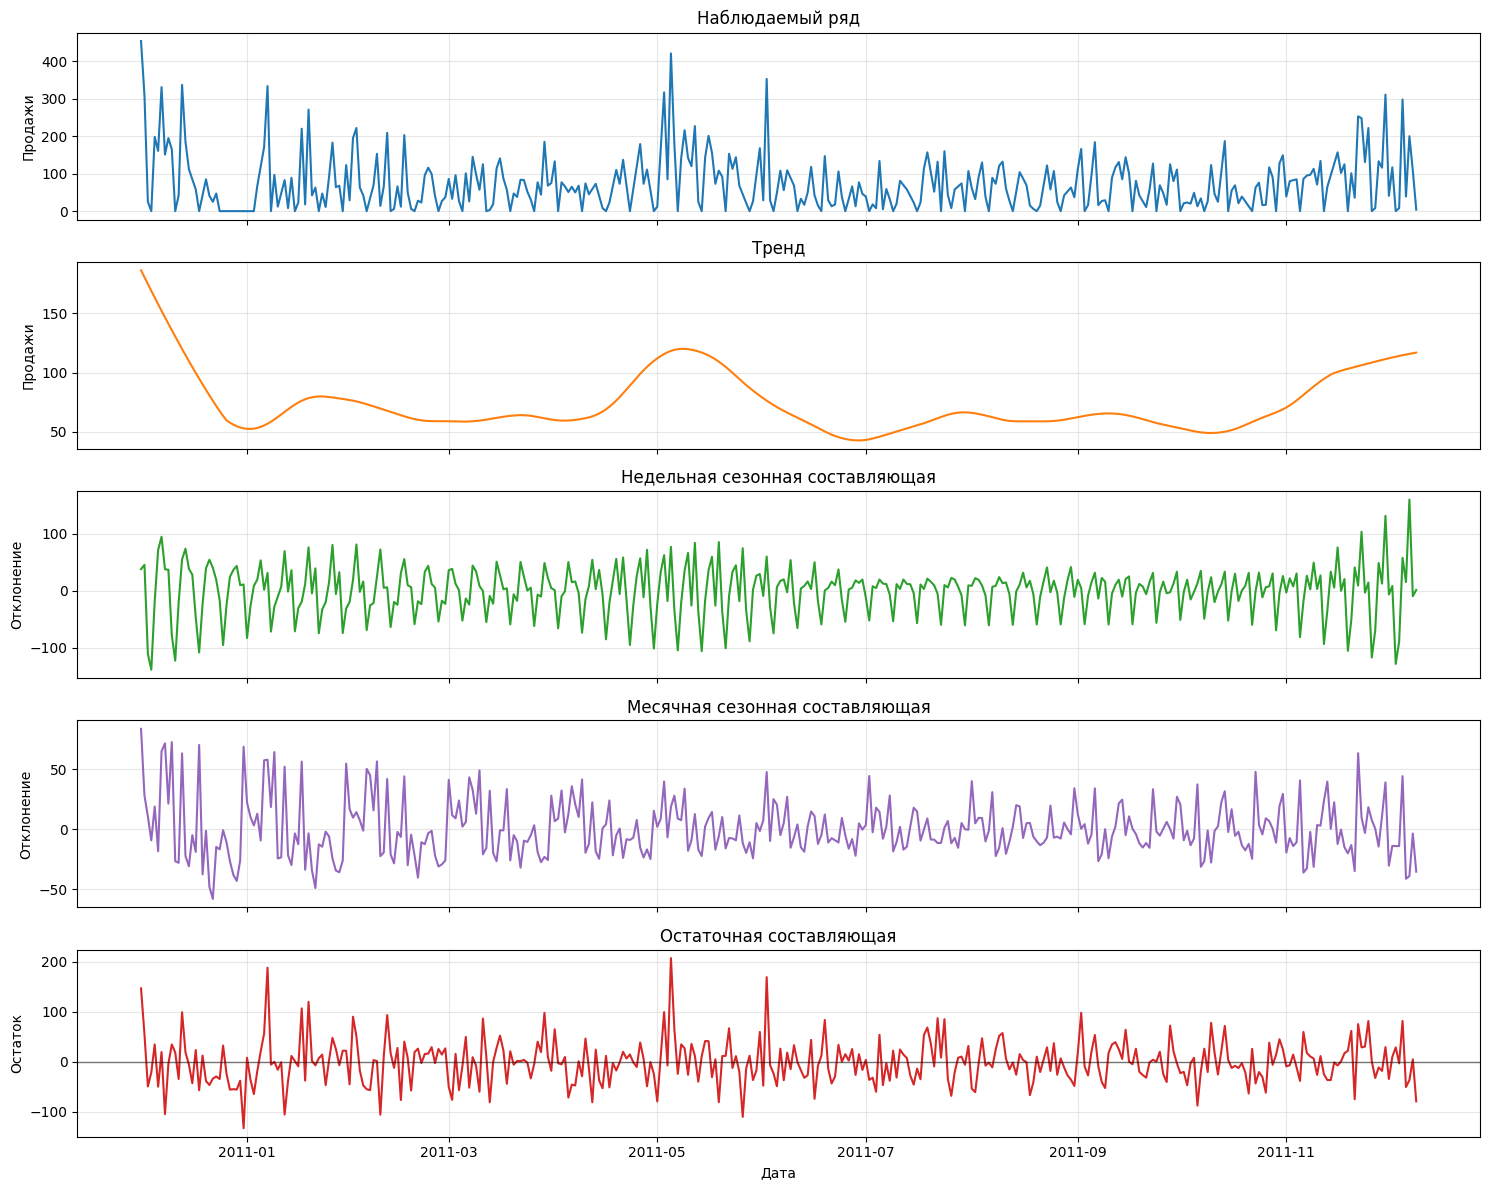

In [ ]:
decomposition_periods = [7, 30]

sales_decomposition = sales_clean.asfreq('D').copy()
missing_for_decomposition = sales_decomposition['Quantity'].isna().sum()


sales_decomposition['Quantity_filled'] = (
    sales_decomposition['Quantity']
    .interpolate(method='time')
    .bfill()
    .ffill()
)

mstl = MSTL(
    sales_decomposition['Quantity_filled'],
    periods=decomposition_periods,
)
mstl_result = mstl.fit()

seasonal_components = mstl_result.seasonal
if isinstance(seasonal_components, pd.Series):
    seasonal_components = seasonal_components.to_frame(name=f'Сезонность {decomposition_periods[0]} дней')
else:
    seasonal_components = seasonal_components.copy()
    seasonal_components.columns = [f'Сезонность {period} дней' for period in decomposition_periods]

decomposition_components = pd.concat(
    [
        sales_decomposition['Quantity_filled'].rename('Наблюдаемый ряд'),
        mstl_result.trend.rename('Тренд'),
        seasonal_components,
        mstl_result.resid.rename('Остатки'),
    ],
    axis=1,
)

seasonal_strengths = []
for column in seasonal_components.columns:
    strength = max(
        0,
        1 - np.var(mstl_result.resid) / np.var(seasonal_components[column] + mstl_result.resid),
    )
    seasonal_strengths.append(round(strength, 3))

trend_strength = max(
    0,
    1 - np.var(mstl_result.resid) / np.var(mstl_result.trend + mstl_result.resid),
)

decomposition_summary = pd.DataFrame({
    'Показатель': [
        'Метод',
        'Периоды сезонности',
        'Пропусков, заполненных интерполяцией',
        'Сила недельной сезонности',
        'Сила месячной сезонности',
        'Сила тренда',
    ],
    'Значение': [
        'MSTL',
        ', '.join(f'{period} дней' for period in decomposition_periods),
        missing_for_decomposition,
        seasonal_strengths[0],
        seasonal_strengths[1] if len(seasonal_strengths) > 1 else np.nan,
        round(trend_strength, 3),
    ],
})

display(decomposition_summary)
display(decomposition_components.head())

fig, axes = plt.subplots(5, 1, figsize=(15, 12), sharex=True)

axes[0].plot(decomposition_components.index, decomposition_components['Наблюдаемый ряд'])
axes[0].set_title('Наблюдаемый ряд')
axes[0].set_ylabel('Продажи')

axes[1].plot(decomposition_components.index, decomposition_components['Тренд'], color='tab:orange')
axes[1].set_title('Тренд')
axes[1].set_ylabel('Продажи')

axes[2].plot(decomposition_components.index, seasonal_components.iloc[:, 0], color='tab:green')
axes[2].set_title('Недельная сезонная составляющая')
axes[2].set_ylabel('Отклонение')

axes[3].plot(decomposition_components.index, seasonal_components.iloc[:, 1], color='tab:purple')
axes[3].set_title('Месячная сезонная составляющая')
axes[3].set_ylabel('Отклонение')

axes[4].plot(decomposition_components.index, decomposition_components['Остатки'], color='tab:red')
axes[4].axhline(0, color='black', linewidth=1, alpha=0.5)
axes[4].set_title('Остаточная составляющая')
axes[4].set_ylabel('Остаток')
axes[4].set_xlabel('Дата')

for ax in axes:
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


ВЫВОДЫ ПО ДЕКОМПОЗИЦИИ

Для декомпозиции я выбрал MSTL, потому что в ряду есть не только недельный цикл, но и более длинные колебания примерно на уровне месяца. Поэтому я использую периоды 7 и 30 дней.

Тренд показывает общий уровень продаж без регулярных сезонных колебаний. Его сила около 0.305, то есть долгосрочная динамика есть, но она не главная часть ряда.

Недельная сезонность выражена сильнее всего. Ее сила около 0.494, что хорошо согласуется с графиками ACF, FFT и CWT. Месячная компонента слабее, ее сила около 0.265, но она тоже заметна.

Остатки показывают то, что не объясняется трендом и сезонностью. В итоге MSTL здесь подходит лучше, чем обычный STL, потому что позволяет отдельно увидеть недельную и месячную составляющие.

СТАЦИОНАРНОСТЬ

,Ряд,Тест,H0,Статистика,p-value,Вывод
0,Исходный ряд,ADF,"есть единичный корень, ряд нестационарен",-4.7112,0.0001,стационарен
1,Исходный ряд,KPSS,ряд стационарен вокруг постоянного уровня,0.2018,0.1000,стационарен


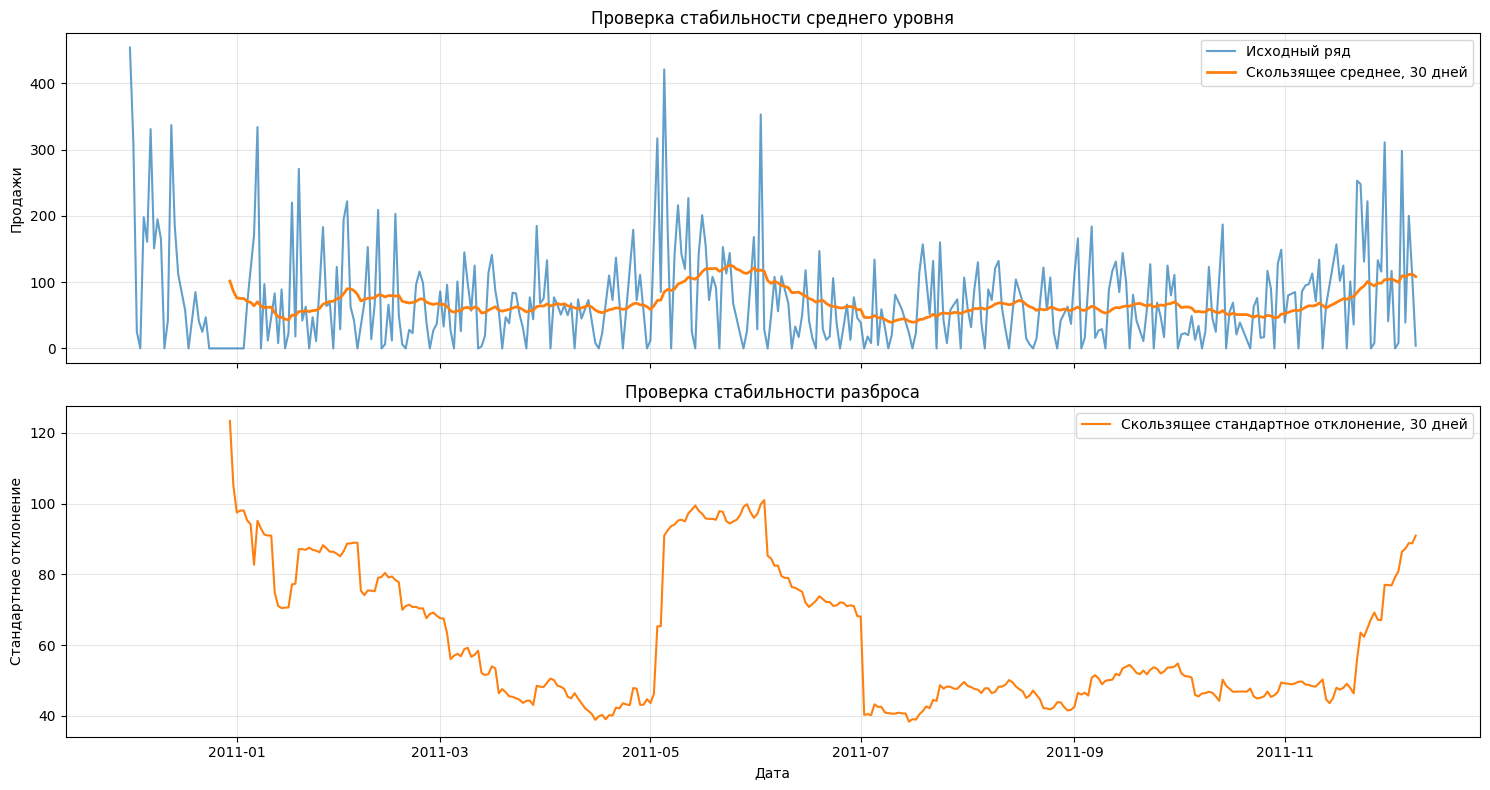

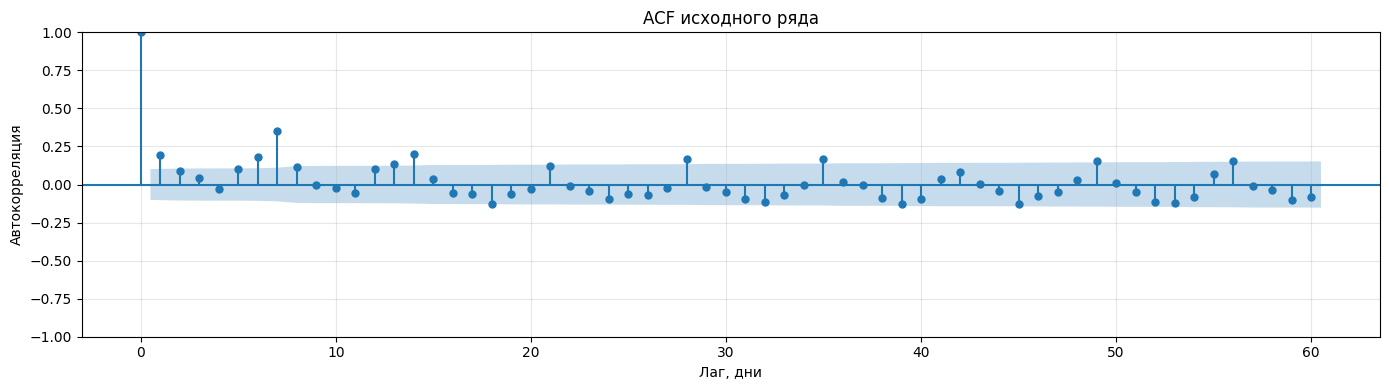

In [67]:
import warnings

stationarity_series = (
    sales_clean.asfreq('D')['Quantity']
    .interpolate(method='time')
    .bfill()
    .ffill()
)

def run_stationarity_tests(values, series_name):
    adf_result = adfuller(values, autolag='AIC')
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        kpss_result = kpss(values, regression='c', nlags='auto')

    return pd.DataFrame([
        {
            'Ряд': series_name,
            'Тест': 'ADF',
            'H0': 'есть единичный корень, ряд нестационарен',
            'Статистика': adf_result[0],
            'p-value': adf_result[1],
            'Вывод': 'стационарен' if adf_result[1] < 0.05 else 'нестационарен',
        },
        {
            'Ряд': series_name,
            'Тест': 'KPSS',
            'H0': 'ряд стационарен вокруг постоянного уровня',
            'Статистика': kpss_result[0],
            'p-value': kpss_result[1],
            'Вывод': 'стационарен' if kpss_result[1] >= 0.05 else 'нестационарен',
        },
    ])

stationarity_results = run_stationarity_tests(stationarity_series, 'Исходный ряд')
display(stationarity_results.round({'Статистика': 4, 'p-value': 4}))

rolling_window = 30
rolling_mean = stationarity_series.rolling(rolling_window).mean()
rolling_std = stationarity_series.rolling(rolling_window).std()

fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True)

axes[0].plot(stationarity_series.index, stationarity_series, label='Исходный ряд', alpha=0.7)
axes[0].plot(rolling_mean.index, rolling_mean, label='Скользящее среднее, 30 дней', linewidth=2)
axes[0].set_title('Проверка стабильности среднего уровня')
axes[0].set_ylabel('Продажи')
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].plot(rolling_std.index, rolling_std, color='tab:orange', label='Скользящее стандартное отклонение, 30 дней')
axes[1].set_title('Проверка стабильности разброса')
axes[1].set_xlabel('Дата')
axes[1].set_ylabel('Стандартное отклонение')
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(14, 4))
plot_acf(stationarity_series, lags=60, ax=ax)
ax.set_title('ACF исходного ряда')
ax.set_xlabel('Лаг, дни')
ax.set_ylabel('Автокорреляция')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


ВЫВОДЫ ПО СТАЦИОНАРНОСТИ

Я проверил ряд двумя тестами. ADF проверяет наличие единичного корня, а KPSS проверяет стационарность вокруг постоянного уровня.

По ADF получилось p-value меньше 0.05, поэтому гипотеза о нестационарности отвергается. По KPSS получилось p-value не меньше 0.05, поэтому гипотеза о стационарности не отвергается.

Оба теста дают один и тот же практический вывод: очищенный исходный ряд можно считать стационарным, поэтому дополнительное преобразование не требуется.

ACF дополнительно показывает недельную структуру: заметны лаги около 7, 14 и 21 дня. Скользящее среднее и стандартное отклонение колеблются, но сильного устойчивого ухода не видно.

ШАГ 6. ФУНКЦИИ

Основные шаги анализа я вынес в файл ts_functions.py. Ниже я заново запускаю весь пайплайн через функции, чтобы проверить, что ноутбук можно воспроизвести последовательным запуском.

,Этап,Количество
0,Дневной ряд,374
1,Итоговый ряд после очистки,350
2,Найденные аномалии,17
3,Удаленные недопустимые нули,7
4,Оставленные календарные нули,62


,Metric,Value
0,Mean,73.422857
1,Variance,5754.548473
2,Standard deviation,75.858740


,Month,Average sales
4,May,119.750000
10,November,104.000000
11,December,96.871795
0,January,72.931034
8,September,71.724138


,Series,Test,H0,Statistic,p-value,Conclusion
0,Original,ADF,"unit root, non-stationary",-4.7112,0.0001,stationary
1,Original,KPSS,stationary around constant level,0.2018,0.1000,stationary


,Компонента,Сила
0,seasonal_7,0.494
1,seasonal_30,0.265
2,trend,0.305


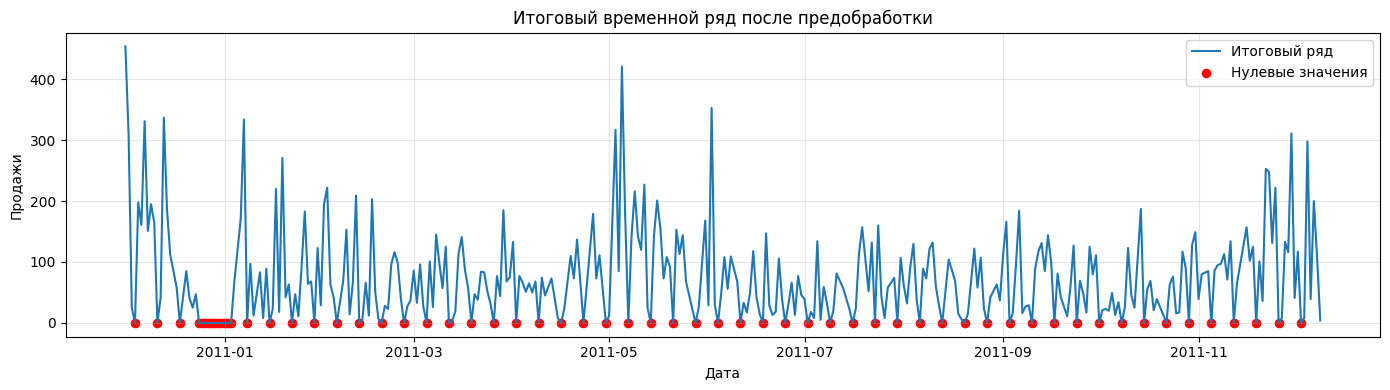

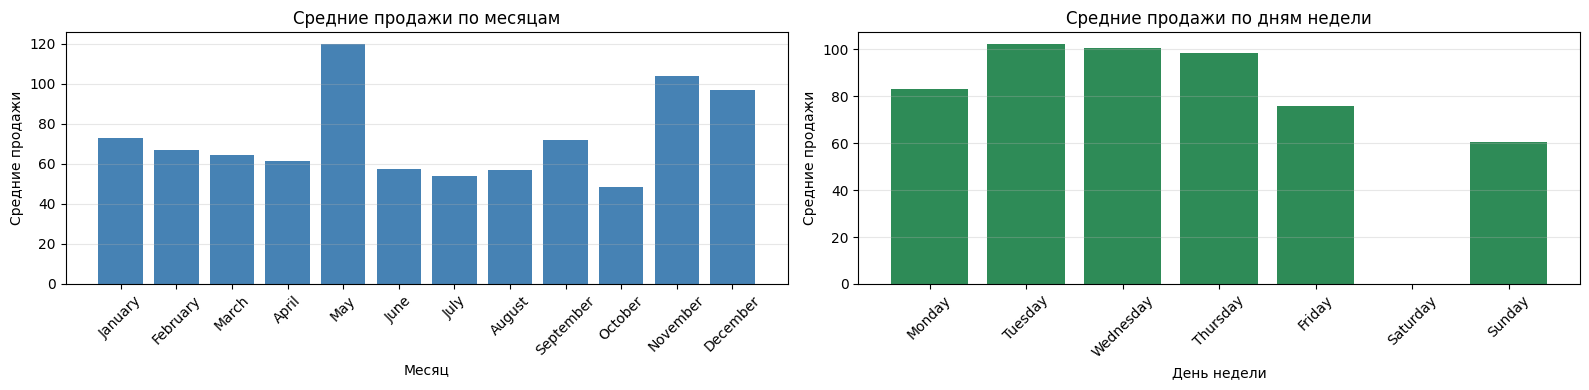

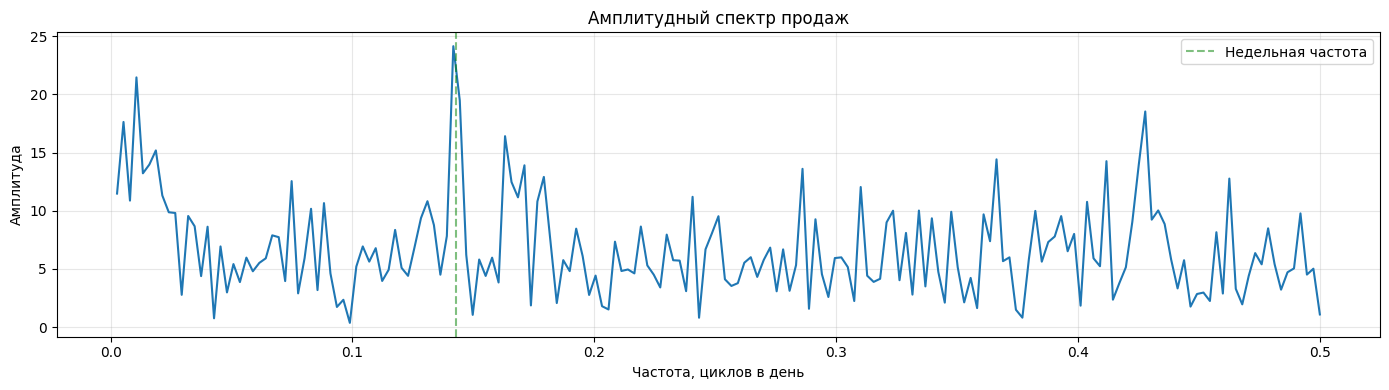

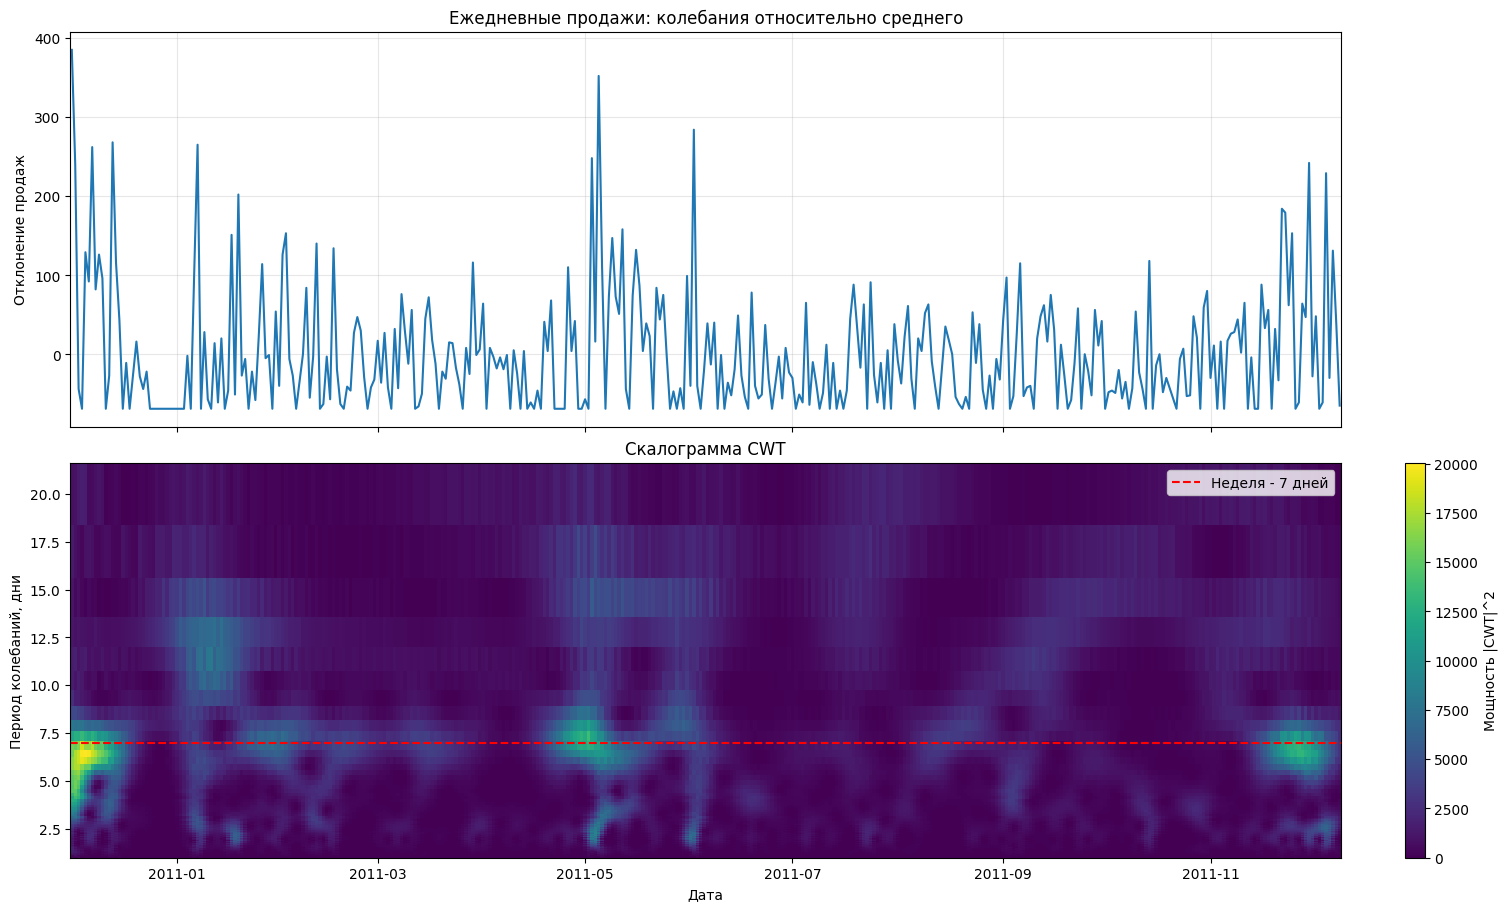

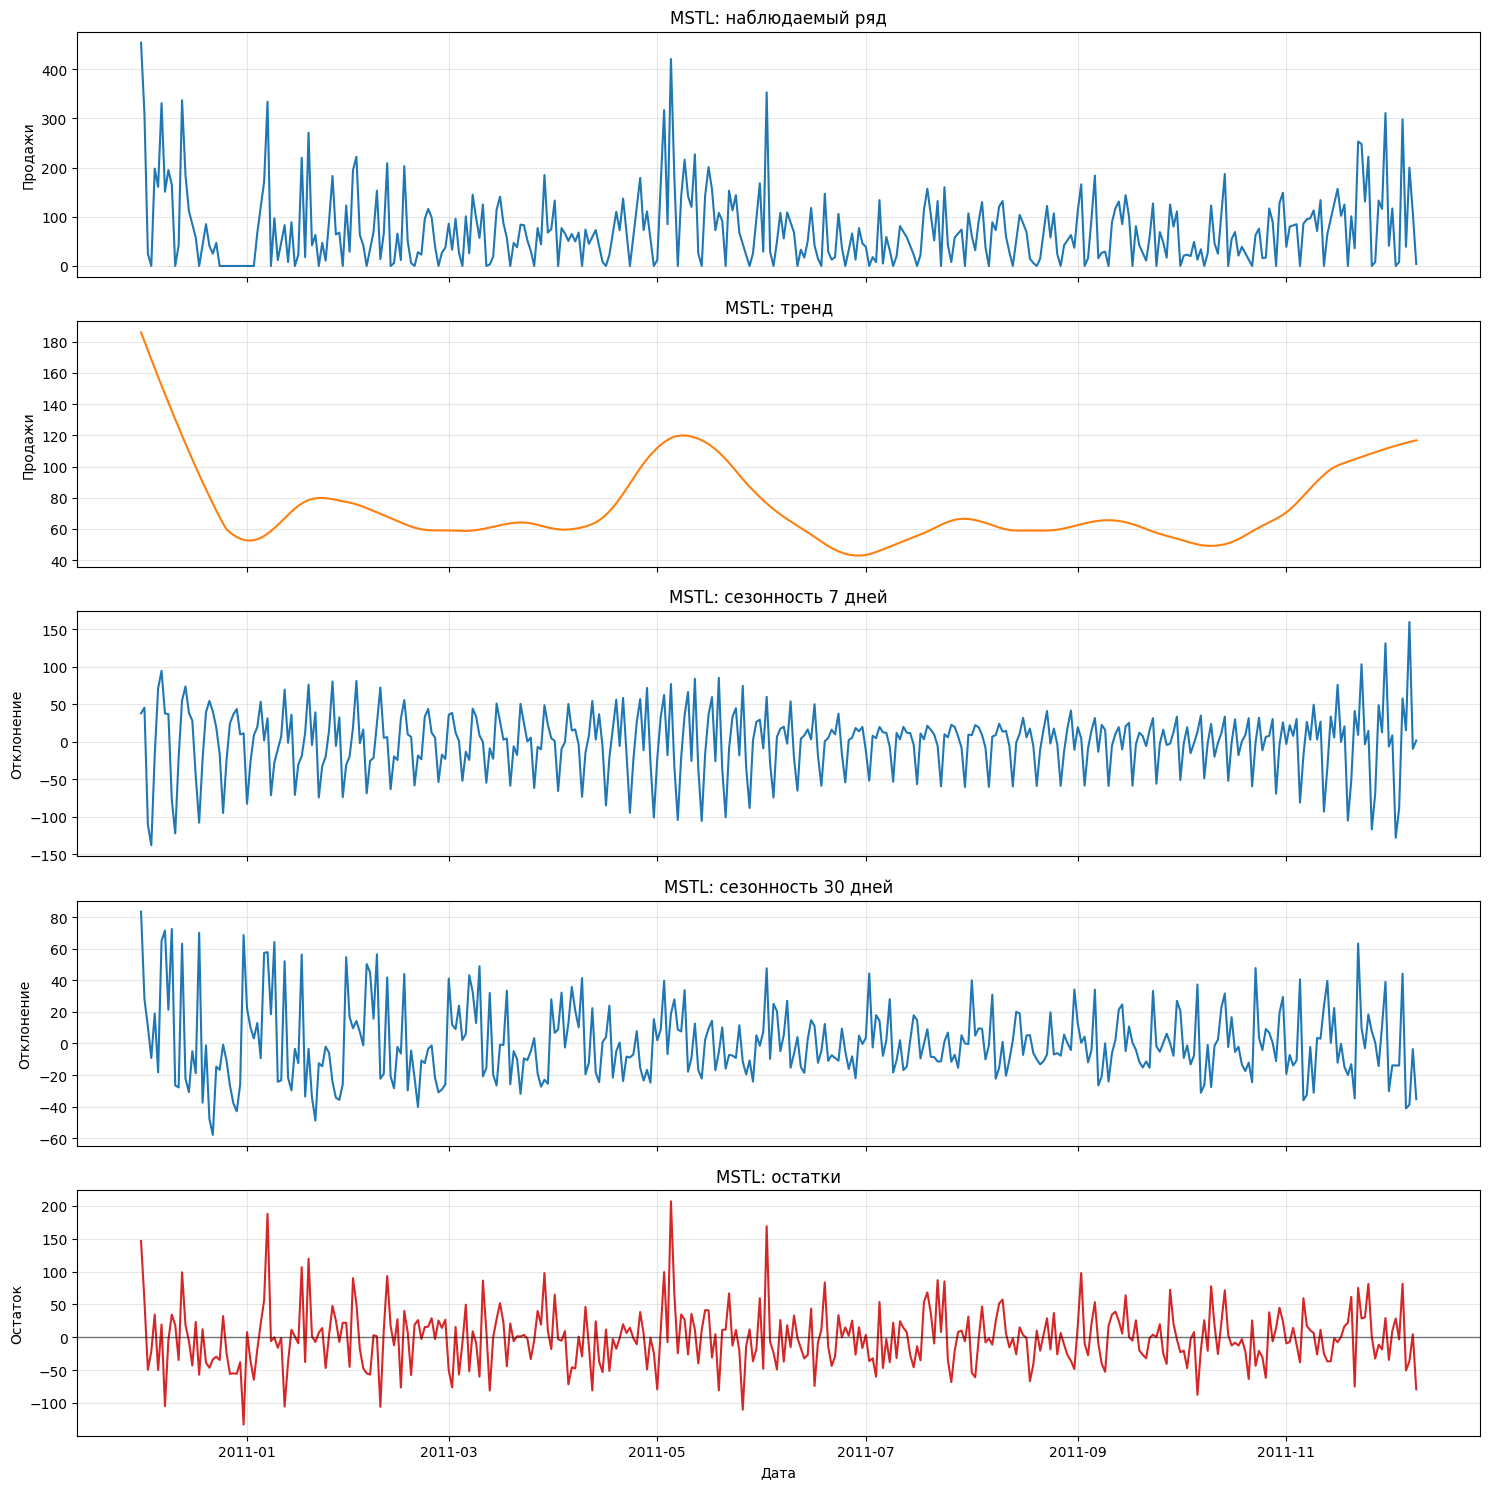

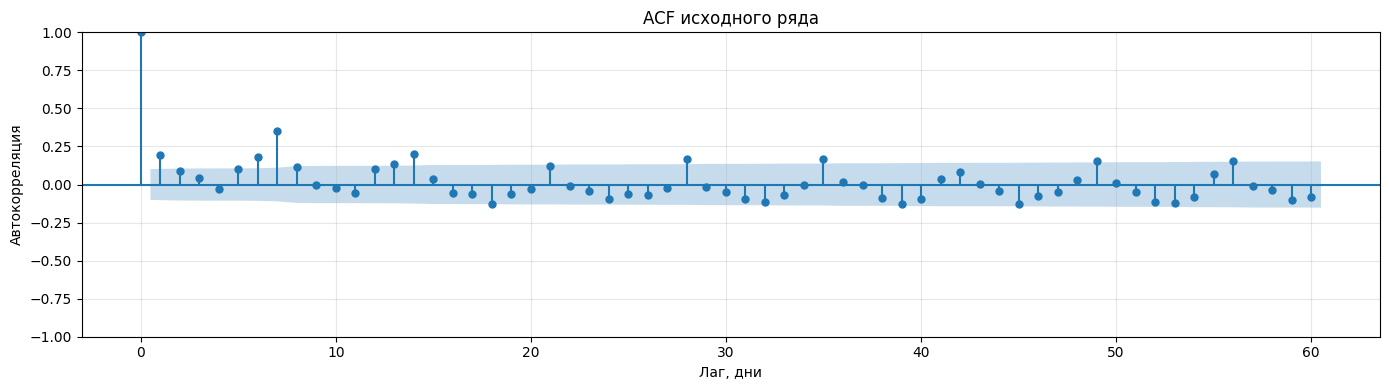

In [70]:
import importlib
import ts_functions as tsf

importlib.reload(tsf)

analysis_results = tsf.run_analysis_pipeline(
    df,
    stock_code='85123A',
    window=14,
    iqr_multiplier=3,
    holiday_start='2010-12-24',
    holiday_end='2011-01-03',
)

sales_from_functions = analysis_results['sales']
sales_clean_from_functions = analysis_results['sales_clean']

pipeline_summary = pd.DataFrame({
    'Этап': [
        'Дневной ряд',
        'Итоговый ряд после очистки',
        'Найденные аномалии',
        'Удаленные недопустимые нули',
        'Оставленные календарные нули',
    ],
    'Количество': [
        len(sales_from_functions),
        len(sales_clean_from_functions),
        len(analysis_results['anomaly_points']),
        len(analysis_results['dropped_zero_points']),
        len(analysis_results['ignored_zero_points']),
    ],
})

display(pipeline_summary)
display(analysis_results['statistics'])
display(analysis_results['monthly_average'].sort_values('Average sales', ascending=False).head())
display(analysis_results['stationarity'].round({'Statistic': 4, 'p-value': 4}))

seasonality_summary = pd.DataFrame({
    'Компонента': list(analysis_results['seasonal_strengths'].keys()) + ['trend'],
    'Сила': list(analysis_results['seasonal_strengths'].values()) + [analysis_results['trend_strength']],
})
display(seasonality_summary.round({'Сила': 3}))

figures = tsf.plot_pipeline_results(analysis_results)
